# 作業二：遷移式學習做 BTS 成員辨識器

參考老師的「八哥辨識器」範例，運用 **遷移式學習 (Transfer Learning)** 技術，
用極少量照片訓練出一個能辨識 BTS 成員的影像分類器。

### 核心概念
- **遷移式學習**：借用在 ImageNet（1400 萬張圖片）上訓練好的 ResNet50V2 模型
- 將它當作「特徵萃取器」，只訓練最後的分類層
- 即使每人只有 ~10 張照片，也能有不錯的辨識效果

### 辨識成員（全員 7 位）

| 英文代號 | 本名 | 藝名 |
|---|---|---|
| RM | 金南俊 | RM |
| Jin | 金碩珍 | Jin |
| SUGA | 閔玧其 | SUGA |
| JHope | 鄭號錫 | J-Hope |
| Jimin | 朴智旻 | Jimin |
| V | 金泰亨 | V |
| Jungkook | 田柾國 | Jungkook |


In [18]:
# ===================================================
# ★ BTS 全員辨識器設定（7 位成員）
# ===================================================
category_en = "RM,Jin,SUGA,JHope,Jimin,V,Jungkook"

# 中文顯示名稱
category_zh = "RM_金南俊,Jin_金碩珍,SUGA_閔玧其,JHope_鄭號錫,Jimin_朴智旻,V_金泰亨,Jungkook_田柾國"

# APP 名稱
title = "BTS 全員辨識器"

# APP 說明
description = "上傳一張 BTS 成員的照片，我會告訴你他是誰！支援全部 7 位成員辨識"


### 1. 安裝與載入套件


In [19]:
!pip install gradio -q


In [20]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import os

import tensorflow as tf
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.applications.resnet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical

import PIL.Image as Image
import gradio as gr

print(f"TensorFlow 版本: {tf.__version__}")


TensorFlow 版本: 2.19.0


### 2. 建立資料夾 & 上傳照片

執行下方 Cell 後，左側檔案區會出現 7 個資料夾：
- `RM/` → 放 RM 的個人照
- `Jin/` → 放 Jin 的個人照
- `SUGA/` → 放 SUGA 的個人照
- `JHope/` → 放 J-Hope 的個人照
- `Jimin/` → 放 Jimin 的個人照
- `V/` → 放 V 的個人照
- `Jungkook/` → 放 Jungkook 的個人照

**每個資料夾放入 12~15 張該成員的照片**（臉部清楚的個人照）
→ 直接從電腦 **拖拉** 到對應資料夾即可！


In [21]:
import os

# 1. 定義類別與參數 (確保 N, categories 有值)
categories = category_en.split(',')
labels = category_zh.split(',')
N = len(categories)

# 你的檔案 ID
file_id = '13WUwRgtOT1bcsmz7cFV2pyV7iFle65Ec'

# 2. 執行自動下載
if not os.path.exists('/content/BTS_photos'):
    print("⏳ 正在從雲端下載資料集，請稍候...")
    !gdown --id {file_id} -O bts_photos.zip
    !unzip -q bts_photos.zip -d /content/
    print("✅ 資料集下載並解壓完成！")
else:
    print("💡 資料集已存在，跳過下載。")

# 3. 設定基礎路徑
base_dir = '/content/BTS_photos/'

print(f"📊 類別數: {N}")
print(f"📂 目前設定的讀取路徑為: {base_dir}")


💡 資料集已存在，跳過下載。
📊 類別數: 7
📂 目前設定的讀取路徑為: /content/BTS_photos/


### 3. 載入圖片資料

將每個資料夾的照片讀入，統一縮放為 224×224（ResNet 的輸入大小）。


In [22]:
data = []
target = []

for i in range(N):
    thedir = base_dir + categories[i]
    # 過濾隱藏檔和非圖片檔
    file_names = [f for f in os.listdir(thedir)
                  if not f.startswith('.') and f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))]
    print(f"📁 {categories[i]}（{labels[i]}）: {len(file_names)} 張照片")

    for fname in file_names:
        img_path = os.path.join(thedir, fname)
        try:
            img = load_img(img_path, target_size=(224, 224))
            x = img_to_array(img)
            data.append(x)
            target.append(i)
        except Exception as e:
            print(f"  ⚠️ 跳過 {fname}: {e}")

data = np.array(data)
target = np.array(target)

print(f"\n✅ 共載入 {len(data)} 張照片，shape = {data.shape}")


📁 RM（RM_金南俊）: 16 張照片
📁 Jin（Jin_金碩珍）: 17 張照片
📁 SUGA（SUGA_閔玧其）: 15 張照片
📁 JHope（JHope_鄭號錫）: 18 張照片
📁 Jimin（Jimin_朴智旻）: 16 張照片
📁 V（V_金泰亨）: 16 張照片
📁 Jungkook（Jungkook_田柾國）: 13 張照片

✅ 共載入 111 張照片，shape = (111, 224, 224, 3)


### 4. 隨機瀏覽幾張照片
確認照片有正確讀入。


/tmp/ipykernel_22875/1905054807.py:13: UserWarning: Glyph 37329 (\N{CJK UNIFIED IDEOGRAPH-91D1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22875/1905054807.py:13: UserWarning: Glyph 21335 (\N{CJK UNIFIED IDEOGRAPH-5357}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22875/1905054807.py:13: UserWarning: Glyph 20426 (\N{CJK UNIFIED IDEOGRAPH-4FCA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22875/1905054807.py:13: UserWarning: Glyph 30889 (\N{CJK UNIFIED IDEOGRAPH-78A9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22875/1905054807.py:13: UserWarning: Glyph 29645 (\N{CJK UNIFIED IDEOGRAPH-73CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22875/1905054807.py:13: UserWarning: Glyph 38292 (\N{CJK UNIFIED IDEOGRAPH-9594}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22875/1905054807.py:13: UserWarning: Glyph 29607 (\N{CJK UNIFIED IDEOGRAP

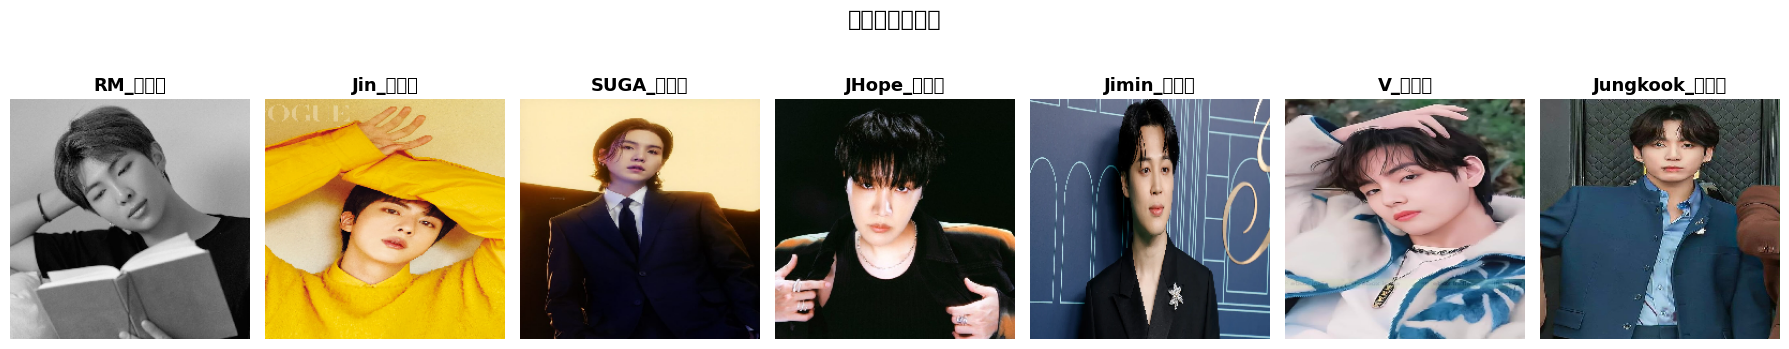

In [23]:
fig, axes = plt.subplots(1, min(N, len(data)), figsize=(18, 4))

# 每類各顯示一張
for i in range(min(N, len(data))):
    idx_list = np.where(target == i)[0]
    if len(idx_list) > 0:
        idx = np.random.choice(idx_list)
        axes[i].imshow(data[idx] / 255)
        axes[i].set_title(labels[i], fontsize=13, fontweight='bold')
        axes[i].axis('off')

plt.suptitle('各成員照片預覽', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


### 5. 用 ResNet50V2 萃取特徵（遷移式學習的核心）

載入在 ImageNet 上訓練好的 ResNet50V2：
- 拿掉最後的分類層 (`include_top=False`)
- 只保留特徵萃取器
- 每張 224×224×3 的照片 → 變成 **2048 維的特徵向量**

In [24]:
print(f"原本的照片張數: {len(data)}")

# 將原本的照片水平翻轉
data_flipped = np.flip(data, axis=2)

# 合併原始照片與翻轉後的照片
data = np.vstack((data, data_flipped))
target = np.concatenate((target, target))

print(f"翻轉增強後的總張數: {len(data)} (模型現在有兩倍的資料可以學了！)")


原本的照片張數: 111
翻轉增強後的總張數: 222 (模型現在有兩倍的資料可以學了！)


In [25]:
# 載入 ResNet50V2（不含頂層分類器，使用 average pooling）
resnet = ResNet50V2(include_top=False, pooling='avg', weights='imagenet')

# ResNet 前處理
data_preprocessed = preprocess_input(data.copy())

# 萃取特徵
print("⏳ 正在用 ResNet50V2 萃取特徵...")
features = resnet.predict(data_preprocessed, verbose=1)
print(f"\n✅ 特徵萃取完成！")
print(f"   每張照片 → {features.shape[1]} 維特徵向量")
print(f"   特徵矩陣 shape = {features.shape}")


⏳ 正在用 ResNet50V2 萃取特徵...
7/7 ━━━━━━━━━━━━━━━━━━━━ 40s 5s/step

✅ 特徵萃取完成！
   每張照片 → 2048 維特徵向量
   特徵矩陣 shape = (222, 2048)


### 6. 建立分類器

在 ResNet 萃取出的 2048 維特徵上，接一個簡單的全連結 (Dense) 網路做分類。
加入 Dropout 防止過擬合（因為訓練資料很少）。


In [26]:
from tensorflow.keras import layers
model = Sequential([
    # 使用 512 個神經元，搭配適度的 Dropout
    layers.Dense(512, input_dim=features.shape[1], activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(N, activation='softmax')
])

# 使用標準學習率，讓收斂快一點
model.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              metrics=['accuracy'])

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,182,215 (4.51 MB)

 Trainable params: 1,182,215 (4.51 MB)

 Non-trainable params: 0 (0.00 B)

### 7. 訓練分類器

因為只訓練最後的分類層（ResNet 的參數是凍結的），所以訓練非常快！


In [27]:
from tensorflow.keras.utils import to_categorical # 確保有載入工具

# 定義標籤（補上這行！）
target_onehot = to_categorical(target, N)

# 接著跑原本的訓練程式
history = model.fit(features, target_onehot,
                    batch_size=8,
                    epochs=100,
                    validation_split=0.2,
                    shuffle=True,
                    verbose=1)




Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.1751 - loss: 2.4093 - val_accuracy: 0.0000e+00 - val_loss: 2.3774
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2316 - loss: 2.0201 - val_accuracy: 0.0000e+00 - val_loss: 2.2268
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3390 - loss: 1.7914 - val_accuracy: 0.0667 - val_loss: 2.1335
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4237 - loss: 1.6553 - val_accuracy: 0.0667 - val_loss: 2.0696
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.4802 - loss: 1.5289 - val_accuracy: 0.1111 - val_loss: 1.8645
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.5311 - loss: 1.3301 - val_accuracy: 0.2667 - val_loss: 1.7173
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.5537 - loss: 1.2539 - val_accuracy: 0.3778 - val_loss: 1.6387
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.5706 - loss: 1.2498 - val_accu

### 8. 訓練曲線
觀察模型是否收斂、是否過擬合。


/tmp/ipykernel_22875/3856128239.py:22: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22875/3856128239.py:22: UserWarning: Glyph 21729 (\N{CJK UNIFIED IDEOGRAPH-54E1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22875/3856128239.py:22: UserWarning: Glyph 36776 (\N{CJK UNIFIED IDEOGRAPH-8FA8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22875/3856128239.py:22: UserWarning: Glyph 35672 (\N{CJK UNIFIED IDEOGRAPH-8B58}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22875/3856128239.py:22: UserWarning: Glyph 22120 (\N{CJK UNIFIED IDEOGRAPH-5668}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22875/3856128239.py:22: UserWarning: Glyph 35347 (\N{CJK UNIFIED IDEOGRAPH-8A13}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_22875/3856128239.py:22: UserWarning: Glyph 32244 (\N{CJK UNIFIED IDEOGRAP

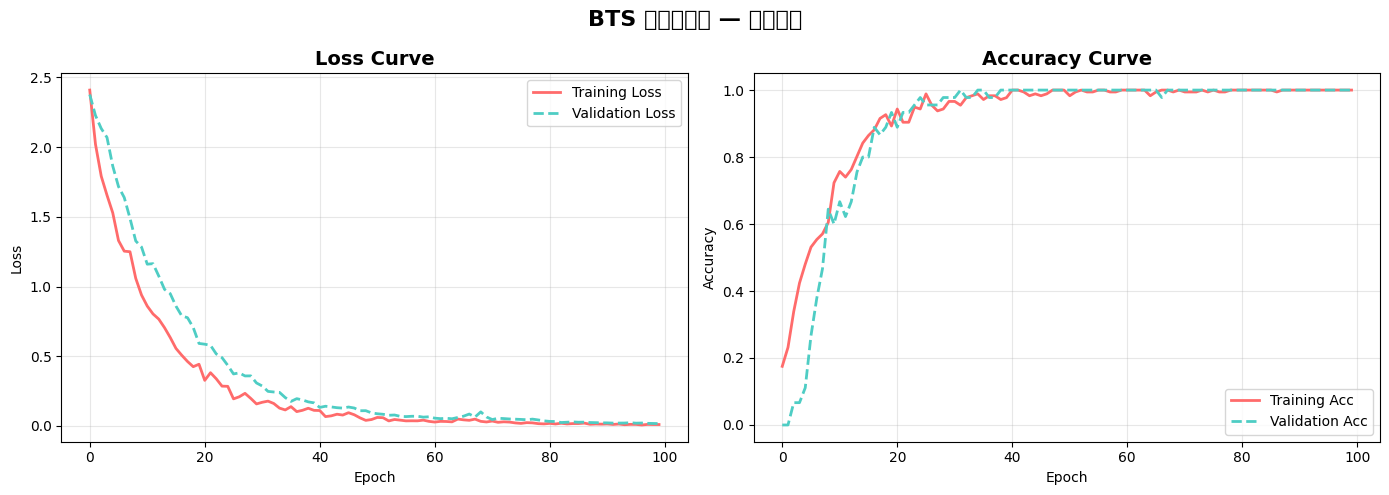

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss 曲線
ax1.plot(history.history['loss'], label='Training Loss', color='#FF6B6B', linewidth=2)
ax1.plot(history.history['val_loss'], label='Validation Loss', color='#4ECDC4', linewidth=2, linestyle='--')
ax1.set_title('Loss Curve', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Accuracy 曲線
ax2.plot(history.history['accuracy'], label='Training Acc', color='#FF6B6B', linewidth=2)
ax2.plot(history.history['val_accuracy'], label='Validation Acc', color='#4ECDC4', linewidth=2, linestyle='--')
ax2.set_title('Accuracy Curve', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(alpha=0.3)

plt.suptitle('BTS 成員辨識器 — 訓練過程', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


### 9. 看結果

上傳任意一張 BTS 成員照片，模型會告訴你他是誰


In [29]:
def classify(image):
    """接收一張圖片，回傳各成員的信心分數"""
    # 調整為 224x224
    img = image.resize((224, 224))
    x = np.array(img, dtype=np.float32)

    # 確保是 RGB 三通道
    if len(x.shape) == 2:
        x = np.stack([x] * 3, axis=-1)
    elif x.shape[2] == 4:
        x = x[:, :, :3]

    x = np.expand_dims(x, axis=0)

    # ResNet 前處理 + 特徵萃取
    x = preprocess_input(x)
    feat = resnet.predict(x, verbose=0)

    # 分類器預測
    pred = model.predict(feat, verbose=0)[0]

    # 回傳 {成員名: 信心分數} 字典
    result = {labels[i]: float(pred[i]) for i in range(N)}
    return result


In [30]:
demo = gr.Interface(
    fn=classify,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=N),
    title=title,
    description=description
)

# share=True 會產生一個公開連結，方便分享
demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4d04e491a8b5c131ef.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
